In [1]:
import os
import numpy as np
import deepdish as dd
import pandas as pd
import nibabel as nb
import Functional_Fusion.dataset as fdata # from functional fusion module
import Functional_Fusion.plot as ffpl
import cortico_cereb_connectivity.globals as gl
import cortico_cereb_connectivity.run_model as rm
import cortico_cereb_connectivity.data as cdata
import cortico_cereb_connectivity.cio as cio
import cortico_cereb_connectivity.summarize as cs
import matplotlib.pyplot as plt
import seaborn as sns
import Functional_Fusion.atlas_map as am
import nitools as nt
from pathlib import Path
import warnings
import SUITPy as suit
fig_dir =  '/Users/jdiedrichsen/Dropbox/Talks/2026/10_ENS'
paper_dir = '/Users/jdiedrichsen/Dropbox/papers/Cerebellum_connectivity/Figures'

# Summarize the pattern of cortical-cerebellar connectivity weights by yeo-region

In [2]:
# Preaggregated assignment of Icosahedrons to Ywo networks
yeo_img = nb.load(gl.conn_dir + f'/maps/yeo17_Icosahedron1002.plabel.nii')
yeo_data = yeo_img.get_fdata().squeeze()
# Dictionary with network labels
label_dict = yeo_img.header.get_axis(0).label[0]

In [3]:
# Get the coefficients and standardize by the length of cortical activity and per-voxel input
traindata = gl.traindata_string()
cortex_roi = "Icosahedron1002"
method = 'NNLS'
mNNLS,_ = cs.get_model(traindata,cortex_roi,method,extension='sc_A1_global',norm=True,ynorm=True)


In [4]:
# Get the coefficients and standardize by the length of cortical activity and per-voxel input
traindata = gl.traindata_string()
cortex_roi = "Icosahedron1002"
method = 'L2Reg'
mL2Reg,_ = cs.get_model(traindata,cortex_roi,method,extension='sc_A4_global',norm=True,ynorm=True)

## NNLS on white: total

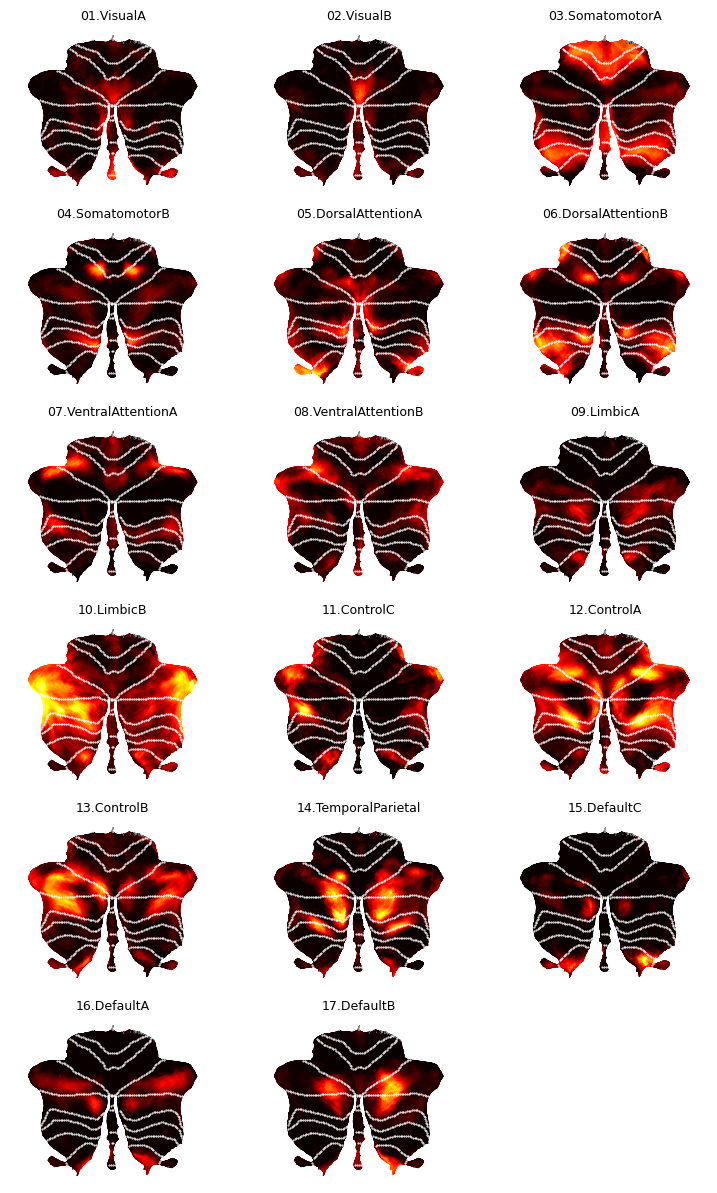

In [5]:
atlas,ainf = am.get_atlas('MNISymC3')
plt.figure(figsize=(9, 15))
for i in range(17):
    plt.subplot(6,3,i+1)
    project = mNNLS.coef_[:,yeo_data== i+1].mean(axis=1)
    nifti_image = atlas.data_to_nifti(project)
    data = suit.vol_to_surf(nifti_image,space='MNISymC')
    suit.flatmap.plot(data, cmap='hot', cscale=[0,0.03], new_figure=False, bordercolor='w', bordersize=1)
    plt.title(label_dict[i+1][0], fontsize=9)
plt.savefig(os.path.join(paper_dir,'yeo17_weights_NNLS.png'),dpi=300,bbox_inches='tight')

## L2reg one white

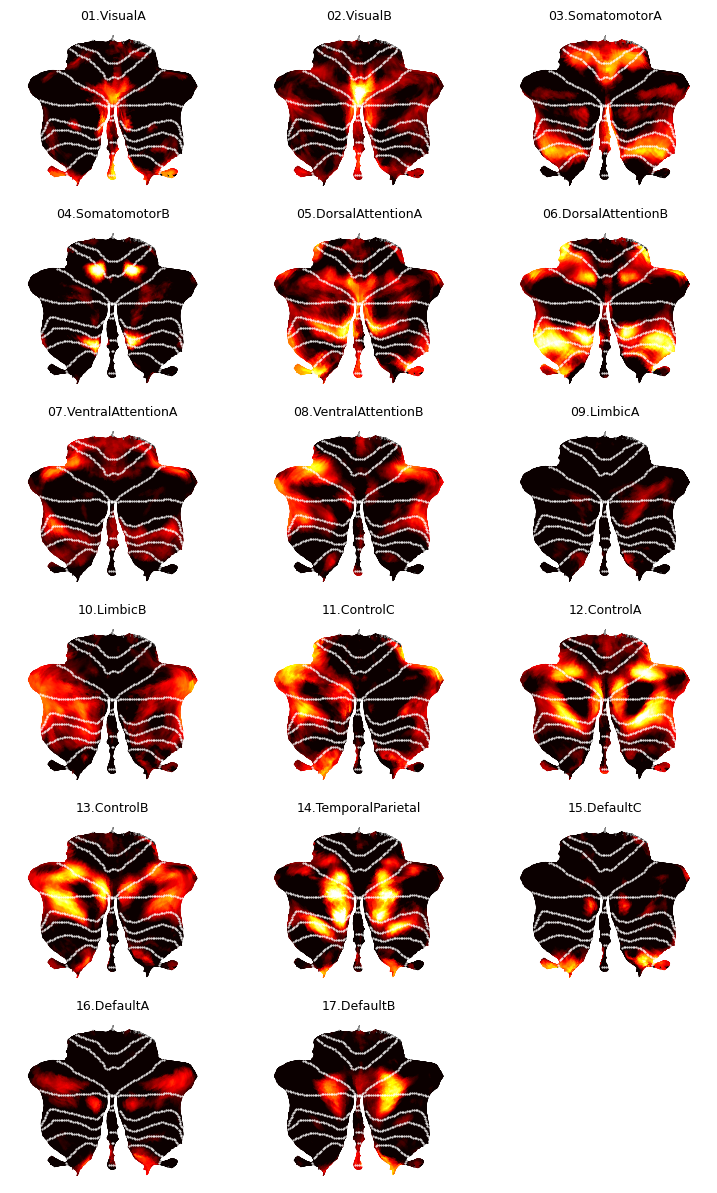

In [7]:
atlas,ainf = am.get_atlas('MNISymC3')
plt.figure(figsize=(9, 15))
for i in range(17):
    plt.subplot(6,3,i+1)
    project = mL2Reg.coef_[:,yeo_data== i+1].mean(axis=1)
    nifti_image = atlas.data_to_nifti(project)
    data = suit.vol_to_surf(nifti_image,space='MNISymC')
    suit.flatmap.plot(data, cmap='hot', cscale=[0,0.03], new_figure=False, bordercolor='w', bordersize=1)
    plt.title(label_dict[i+1][0], fontsize=9)
plt.savefig(os.path.join(paper_dir,'yeo17_weights_L2Reg.png'),dpi=300,bbox_inches='tight')

## NNLS on black 

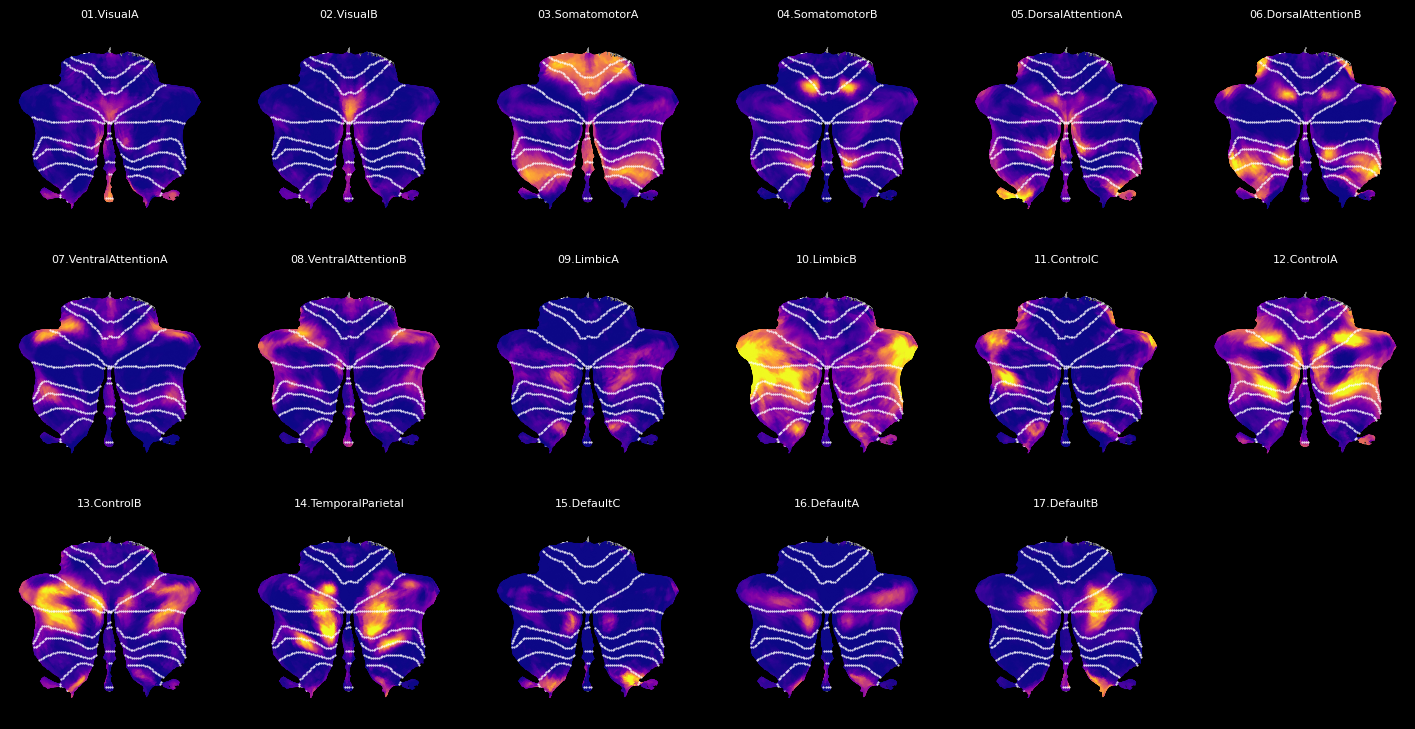

In [8]:
# Talk style: On black background (sum)
atlas,ainf = am.get_atlas('MNISymC3')
plt.figure(figsize=(18, 9), facecolor='k')
for i in range(17):
    plt.subplot(3,6,i+1)
    project = mNNLS.coef_[:,yeo_data== i+1].mean(axis=1)
    nifti_image = atlas.data_to_nifti(project)
    data = suit.vol_to_surf(nifti_image,space='MNISymC')
    suit.flatmap.plot(data,cmap='plasma',cscale=[0,0.02],new_figure=False,bordercolor='w',bordersize=1,backgroundcolor='k')
    plt.title(label_dict[i+1][0], color='w', fontsize=8)
plt.savefig(os.path.join(fig_dir,'yeo17_weights_NNLS.png'),dpi=300,bbox_inches='tight')

## L2Reg on black

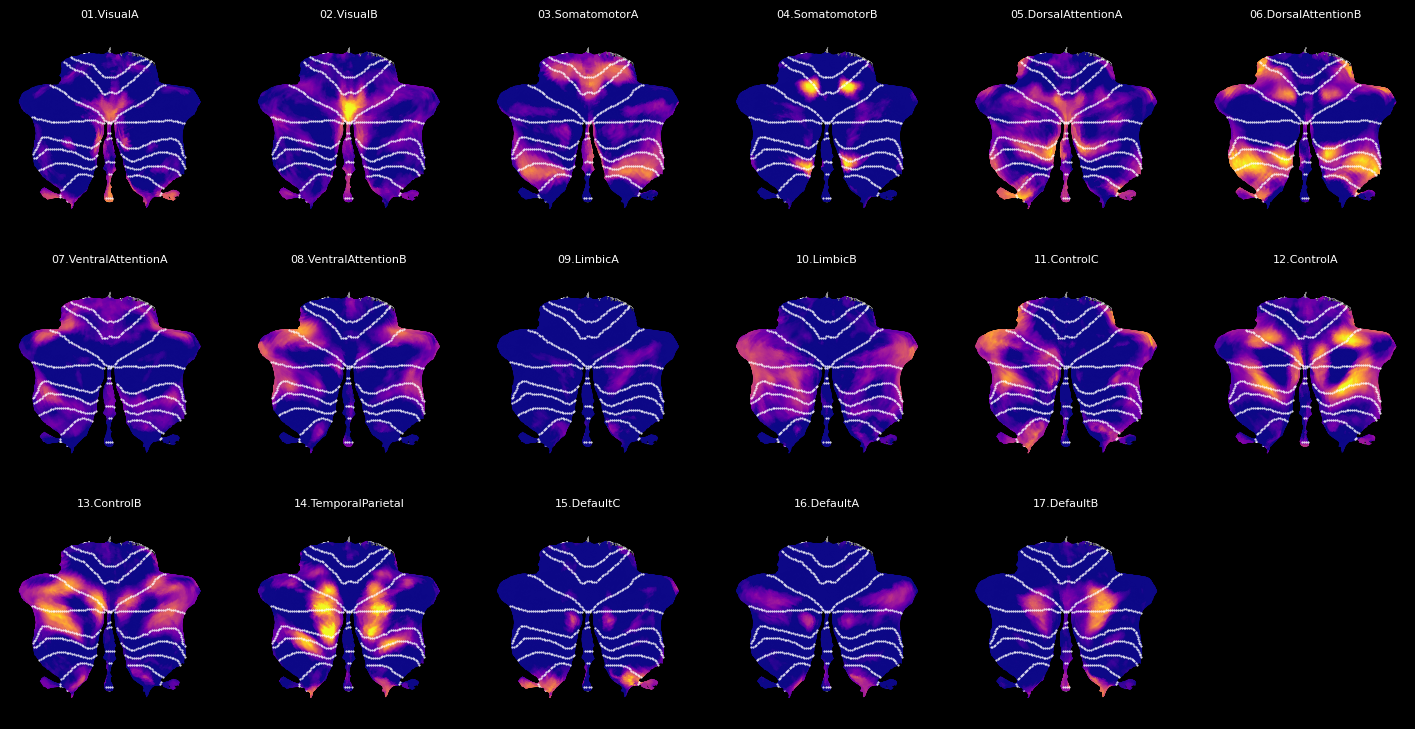

In [9]:
plt.figure(figsize=(18, 9), facecolor='k')
for i in range(17):
    plt.subplot(3,6,i+1)
    project = mL2Reg.coef_[:,yeo_data== i+1].mean(axis=1)
    nifti_image = atlas.data_to_nifti(project)
    data = suit.vol_to_surf(nifti_image,space='MNISymC')
    suit.flatmap.plot(data,cmap='plasma',cscale=[0,0.03],new_figure=False,bordercolor='w',bordersize=1,backgroundcolor='k')
    plt.title(label_dict[i+1][0], color='w', fontsize=8)
plt.savefig(os.path.join(fig_dir,'yeo17_weights_L2Reg.png'),dpi=300,bbox_inches='tight')

## Save individual panels

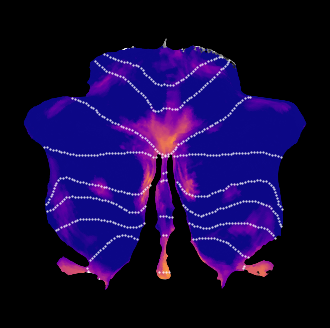

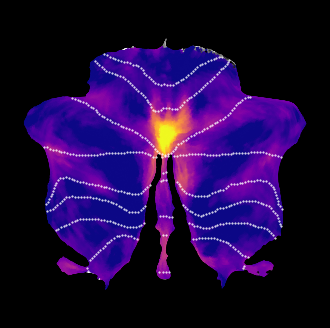

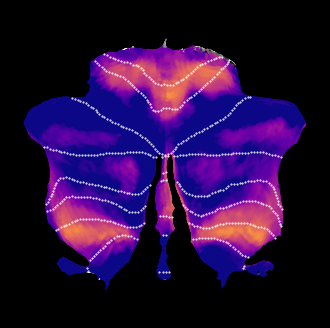

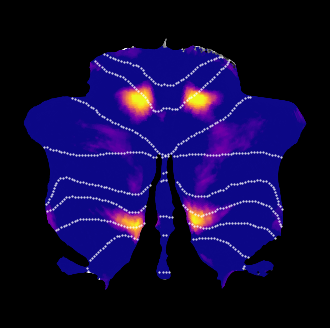

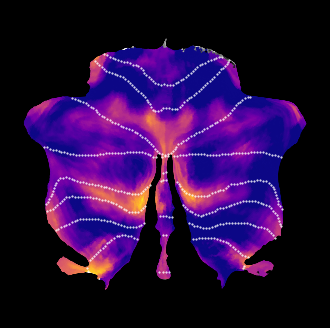

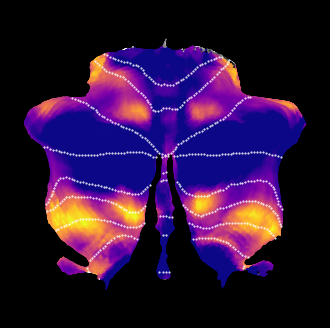

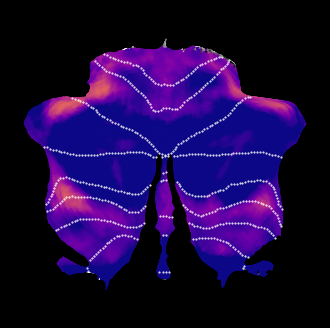

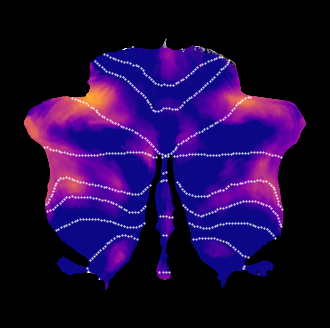

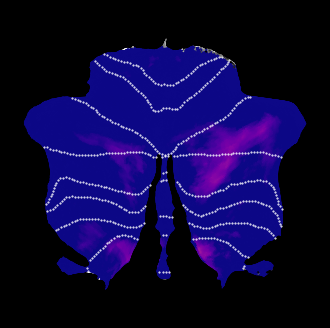

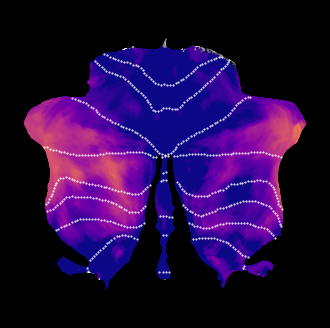

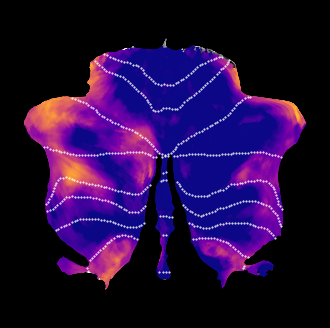

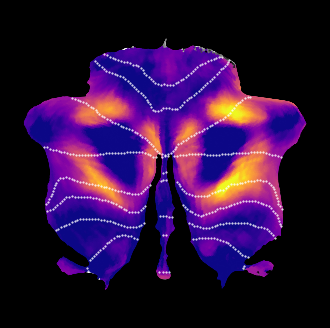

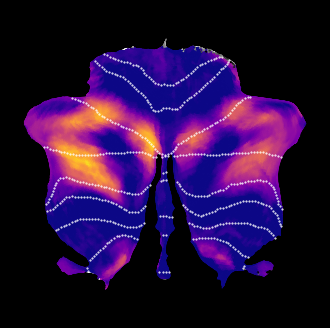

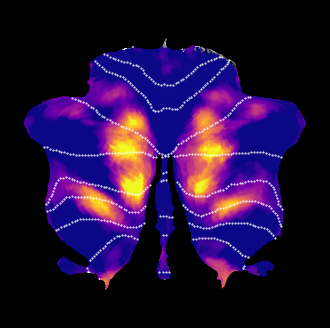

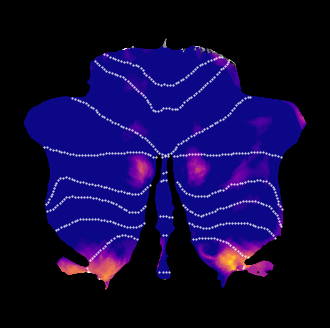

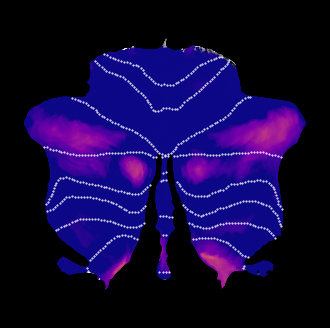

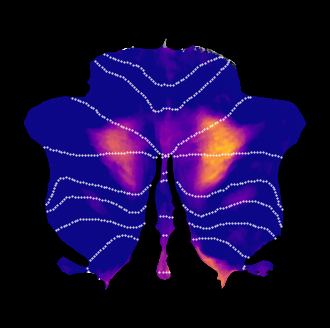

In [10]:
# Save individual Figure files:
for i in range(17):
    plt.figure(figsize=(4, 4), facecolor='k')
    project = mL2Reg.coef_[:,yeo_data== i+1].mean(axis=1)
    nifti_image = atlas.data_to_nifti(project)
    data = suit.vol_to_surf(nifti_image,space='MNISymC')
    suit.flatmap.plot(data,cmap='plasma',cscale=[0,0.03],new_figure=False,bordercolor='w',bordersize=1,backgroundcolor='k')
    plt.savefig(os.path.join(fig_dir,f'yeo17_weights_{i+1}_black.png'),dpi=300,bbox_inches='tight')

## Note on scaling 
The size of the regression coefficients will depend on the scaling of the Y-data, which is only globally normalized
It is quite different across different areas of the cerebellum. 

[See Global scaling Notebook](../3.%20Scaling_in_out_model/Global_dataset_scaling.ipynb) 

The below plots the length of the connectivity weight vector for each cerbellar location, showing the dominance of the hand area (after the addition of the somatotopic dataset). 




<Axes: >

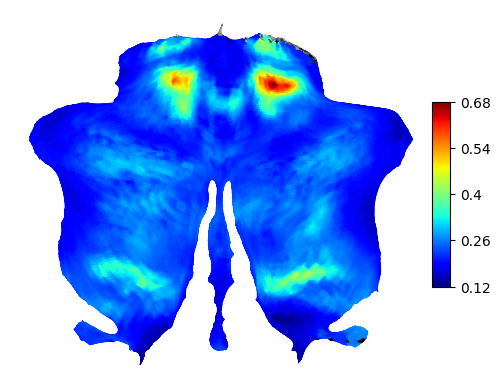

In [12]:
# Journal style: On white (mean)
traindata = gl.traindata_string()
cortex_roi = "Icosahedron1002"
method = 'L2Reg'
model,_ = cs.get_model(traindata,cortex_roi,method,extension='A2_global',norm=True)
vlength = np.sqrt((model.coef_**2).sum(axis=1))
ffpl.plot_cerebellum(vlength,colorbar=True)